### **Exp 9(4) – Hyperparameter-Tuned XGBoost | Feature-Specific Outlier Capping**

1. Separate features and target, excluding customer ID and raw date columns.
2. Split the data into 80% training and 20% testing using stratification.
3. Further split the training data into model training (80%) and validation (20%), keeping the test set untouched.
4. Identify numerical and categorical features for preprocessing.
5. Apply feature-specific outlier capping:
   - Two-sided capping (1st–99th percentile) for selected features.
   - Upper-only capping (99th percentile) for selected right-skewed features.
6. Create a custom OutlierCapper transformer to learn capping limits within each CV training fold and apply them to validation and test data.
7. Impute numerical missing values using the median. Impute categorical missing values with a constant and apply One-Hot Encoding (OHE).
8. Handle class imbalance using scale_pos_weight, calculated from the model training data.
9. Build an XGBoost pipeline combining outlier capping, preprocessing, and classification.
10. RandomizedSearchCV with 30 iterations and 5-Fold Stratified CV is used to tune XGBoost hyperparameters based on PR-AUC.
11. The best model generates churn probabilities on the validation set.
12. Perform fine-grained threshold analysis (0.05–0.95, with 0.01 intervals) and select the threshold with the highest F1 Score.
13. Apply the selected threshold to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
14. Evaluate model performance using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
15. Perform diagnostic cross-validation and analyse the top 20 feature importances.
16. Display the best hyperparameters, CV PR-AUC, selected threshold, test PR-AUC, and test F1 Score.

this experiment incorporates changes to the original Exp 4 model based on outlier detection and treatment.   
Exp 9(4) as took the best-performing XGBoost Classifier model from Exp4 and carried it forward as a new experiment under Exp9

### 0. IMPORT LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)

In [2]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

### 1. SEPARATE FEATURES AND TARGET

In [3]:
date_cols = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']
X = df.drop(columns=['id', 'churn'] + date_cols, errors='ignore')
y = df['churn']

print("Dataset Shape:", X.shape)
print("\nTotal Missing Values:", X.isna().sum().sum())
print("\nTarget Distribution:")
print(y.value_counts())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Dataset Shape: (14606, 104)

Total Missing Values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64


### 2. ORIGINAL TRAIN TEST SPLIT

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)


Original Training Data: (11684, 104)
Original Test Data: (2922, 104)


### 3. INTERNAL TRAIN VALIDATION SPLIT

In [5]:
# Test data remains untouched. Validation data is used for threshold selection.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=21, stratify=y_train
)
print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)
print("Final Test Data:", X_test.shape)


Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)
Final Test Data: (2922, 104)


### 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS

In [6]:
categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

print("\nCategorical Columns:")
print(categorical_cols)
print("\nNumber of Numerical Columns:", len(numerical_cols))


Categorical Columns:
['channel_sales', 'has_gas', 'origin_up']

Number of Numerical Columns: 101


### 5. OUTLIER CAPPING CONFIGURATION

In [7]:
two_sided_features = [
    'cons_last_month_diff',
    'forecast_cons_diff',
    'price_consumption_exposure'
]
upper_only_features = [
    'consumption_per_power',
    'cons_12m',
    'cons_last_month',
    'pow_max',
    'forecast_cons_year',
    'imp_cons',
    'net_margin',
    'margin_per_product'
]

two_sided_features = [col for col in two_sided_features if col in numerical_cols]
upper_only_features = [col for col in upper_only_features if col in numerical_cols]

### 6. OUTLIER CAPPING TRANSFORMER

In [8]:
# Limits are learned separately inside each CV training fold.
class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self, two_sided_features=None, upper_only_features=None):
        self.two_sided_features = two_sided_features
        self.upper_only_features = upper_only_features

    def fit(self, X, y=None):
        self.cap_limits_ = {}
        for col in self.two_sided_features or []:
            self.cap_limits_[col] = {
                'lower': X[col].quantile(0.01),
                'upper': X[col].quantile(0.99)
            }
        for col in self.upper_only_features or []:
            self.cap_limits_[col] = {
                'lower': None,
                'upper': X[col].quantile(0.99)
            }
        return self

    def transform(self, X):
        X = X.copy()
        for col, limits in self.cap_limits_.items():
            if limits['lower'] is not None:
                X[col] = X[col].clip(lower=limits['lower'])
            if limits['upper'] is not None:
                X[col] = X[col].clip(upper=limits['upper'])
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

### 7. OUTLIER CAPPING SUMMARY

In [9]:
# This summary uses X_fit only; the model pipeline independently learns
# limits within each CV fold and refits them on all X_fit.
summary_capper = OutlierCapper(
    two_sided_features=two_sided_features,
    upper_only_features=upper_only_features
)
summary_capper.fit(X_fit)
X_fit_capped_summary = summary_capper.transform(X_fit)

cap_summary = []
for col, limits in summary_capper.cap_limits_.items():
    cap_summary.append({
        'Feature': col,
        'Original Min': X_fit[col].min(),
        'Capped Min': X_fit_capped_summary[col].min(),
        'Original Max': X_fit[col].max(),
        'Capped Max': X_fit_capped_summary[col].max(),
        'Lower Limit': limits['lower'],
        'Upper Limit': limits['upper']
    })

cap_summary_df = pd.DataFrame(cap_summary)
print("\n==== OUTLIER CAPPING SUMMARY ====")
print(cap_summary_df.round(3).to_string(index=False))
print("\n==== DATA SHAPES ====")
print("Original Model Training:", X_fit.shape)
print("Capped Model Training:", X_fit_capped_summary.shape)
print("Original Validation:", X_val.shape)
print("Original Test:", X_test.shape)
print("\nMissing Values Before:", X_fit.isna().sum().sum())
print("Missing Values After:", X_fit_capped_summary.isna().sum().sum())


==== OUTLIER CAPPING SUMMARY ====
                   Feature  Original Min   Capped Min  Original Max  Capped Max  Lower Limit  Upper Limit
      cons_last_month_diff   -194525.250   -17175.873    449656.000  108349.083   -17175.873   108349.083
        forecast_cons_diff  -6207018.990 -3117199.312      3534.240     -12.313 -3117199.312      -12.313
price_consumption_exposure  -2077380.985   -97701.812    481476.438    7618.340   -97701.812     7618.340
     consumption_per_power         0.000        0.000    590028.897  195483.412          NaN   195483.412
                  cons_12m         0.000        0.000   6207104.000 3118110.000          NaN  3118110.000
           cons_last_month         0.000        0.000    771203.000  382647.000          NaN   382647.000
                   pow_max         3.300        3.300       320.000      78.480          NaN       78.480
        forecast_cons_year         0.000        0.000     70180.000   11532.200          NaN    11532.200
           

### 8. CLASS IMBALANCE RATIO

In [10]:
negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()
scale_pos_weight_value = negative_count / positive_count

print("\n==== CLASS IMBALANCE ====")
print("Negative Class:", negative_count)
print("Positive Class:", positive_count)
print("Scale Pos Weight:", round(scale_pos_weight_value, 4))


==== CLASS IMBALANCE ====
Negative Class: 8439
Positive Class: 908
Scale Pos Weight: 9.2941


### 9. PREPROCESSING PIPELINE

In [11]:
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='__MISSING__')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_cols),
        ('cat', categorical_pipeline, categorical_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False,
    n_jobs=1
)

### 10. XGBOOST PIPELINE

In [12]:
xgb_pipeline = Pipeline(steps=[
    ('outlier_capping', OutlierCapper(
        two_sided_features=two_sided_features,
        upper_only_features=upper_only_features
    )),
    ('preprocessing', preprocessor),
    ('model', XGBClassifier(
        objective='binary:logistic',
        eval_metric='aucpr',
        tree_method='hist',
        random_state=42,
        n_jobs=1,
        verbosity=0
    ))
])

### 11. STRATIFIED CROSS VALIDATION

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### 12. HYPERPARAMETER SEARCH SPACE

In [14]:
param_grid = {
    'model__n_estimators': [200, 300, 500, 700],
    'model__max_depth': [2, 3, 4, 5, 6],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__subsample': [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5, 7],
    'model__gamma': [0, 0.1, 0.3, 0.5],
    'model__reg_alpha': [0, 0.01, 0.1, 1],
    'model__reg_lambda': [1, 3, 5, 10],
    'model__scale_pos_weight': [
        1,
        scale_pos_weight_value * 0.5,
        scale_pos_weight_value * 0.75,
        scale_pos_weight_value
    ]
}

### 13. RANDOMIZED SEARCH CV

In [15]:
random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

### 14. FIT RANDOMIZED SEARCH

In [16]:
# Use raw X_fit. Outlier capping is performed inside the pipeline.
random_search.fit(X_fit, y_fit)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'model__colsample_bytree': [0.6, 0.7, ...], 'model__gamma': [0, 0.1, ...], 'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [2, 3, ...], ...}"
,n_iter,30
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


### 15. BEST HYPERPARAMETERS

In [17]:
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)
print("\nBest CV PR-AUC:", round(random_search.best_score_, 4))


==== BEST HYPERPARAMETERS ====
{'model__subsample': 0.9, 'model__scale_pos_weight': np.float64(4.647026431718062), 'model__reg_lambda': 5, 'model__reg_alpha': 0.01, 'model__n_estimators': 500, 'model__min_child_weight': 3, 'model__max_depth': 6, 'model__learning_rate': 0.03, 'model__gamma': 0.1, 'model__colsample_bytree': 1.0}

Best CV PR-AUC: 0.2814


### 16. BEST XGBOOST MODEL

In [18]:
best_xgb_pipeline = random_search.best_estimator_

### 17. RANDOMIZED SEARCH RESULTS

In [19]:
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score', ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
result_cols = [
    'param_model__n_estimators',
    'param_model__max_depth',
    'param_model__learning_rate',
    'param_model__subsample',
    'param_model__colsample_bytree',
    'param_model__min_child_weight',
    'param_model__scale_pos_weight',
    'mean_train_score',
    'mean_test_score',
    'std_test_score'
]
print(search_results_df[result_cols].head(10).round(4).to_string(index=False))


==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators  param_model__max_depth  param_model__learning_rate  param_model__subsample  param_model__colsample_bytree  param_model__min_child_weight  param_model__scale_pos_weight  mean_train_score  mean_test_score  std_test_score
                       500                       6                        0.03                     0.9                            1.0                              3                         4.6470            0.9930           0.2814          0.0373
                       700                       4                        0.05                     0.8                            0.8                              1                         1.0000            0.9781           0.2798          0.0320
                       200                       6                        0.03                     0.9                            0.6                              7                         4.6470            0.8414

### 18. VALIDATION PROBABILITIES

In [20]:
y_prob_val = best_xgb_pipeline.predict_proba(X_val)[:, 1]

### 19. PRECISION RECALL CURVE

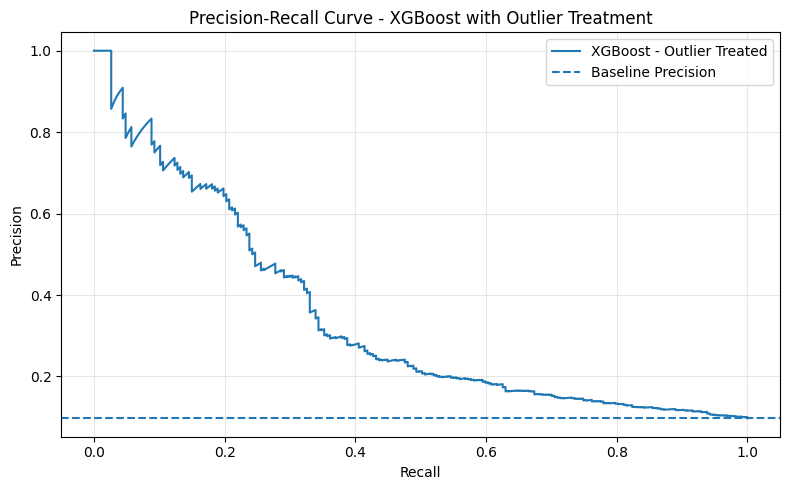

In [21]:
precision, recall, pr_thresholds = precision_recall_curve(y_val, y_prob_val)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label='XGBoost - Outlier Treated')
plt.axhline(y=y_val.mean(), linestyle='--', label='Baseline Precision')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - XGBoost with Outlier Treatment')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 20. FINE-GRAINED THRESHOLD ANALYSIS

In [22]:
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)
    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0)
    })

fine_threshold_df = pd.DataFrame(threshold_results)
print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1069  0.9427    0.1921
      0.06     0.1121  0.9383    0.2003
      0.07     0.1162  0.9163    0.2062
      0.08     0.1183  0.8899    0.2089
      0.09     0.1226  0.8590    0.2145
      0.10     0.1247  0.8326    0.2169
      0.11     0.1304  0.8150    0.2248
      0.12     0.1344  0.7930    0.2299
      0.13     0.1394  0.7753    0.2362
      0.14     0.1430  0.7489    0.2401
      0.15     0.1471  0.7137    0.2440
      0.16     0.1548  0.6960    0.2532
      0.17     0.1611  0.6740    0.2600
      0.18     0.1633  0.6344    0.2597
      0.19     0.1738  0.6300    0.2724
      0.20     0.1799  0.6079    0.2777
      0.21     0.1888  0.5947    0.2866
      0.22     0.1943  0.5683    0.2896
      0.23     0.2000  0.5463    0.2928
      0.24     0.2045  0.5198    0.2935
      0.25     0.2099  0.5022    0.2961
      0.26     0.2194  0.4890    0.3029
      0.27     0.2309  0.4802    0.31

### 21. THRESHOLD PERFORMANCE VISUALIZATION

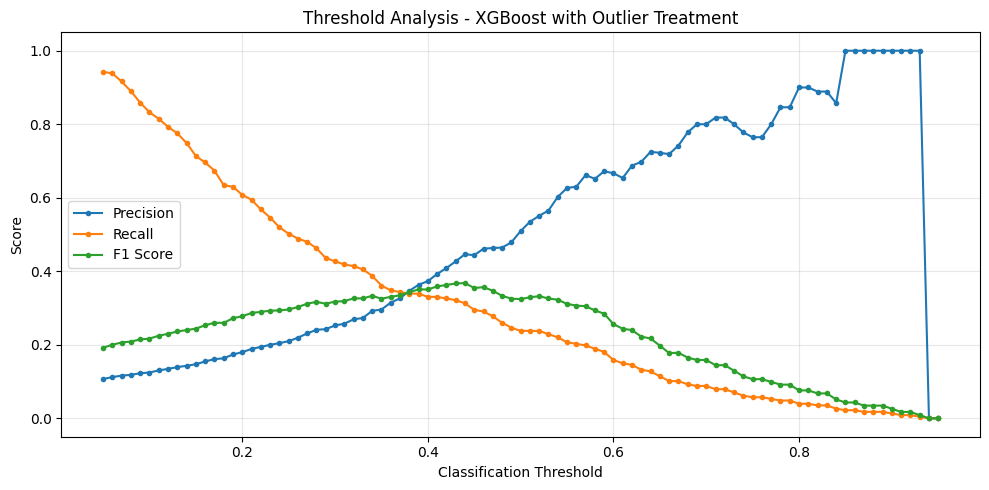

In [23]:
plt.figure(figsize=(10, 5))
plt.plot(fine_threshold_df['Threshold'], fine_threshold_df['Precision'],
         marker='o', markersize=3, label='Precision')
plt.plot(fine_threshold_df['Threshold'], fine_threshold_df['Recall'],
         marker='o', markersize=3, label='Recall')
plt.plot(fine_threshold_df['Threshold'], fine_threshold_df['F1 Score'],
         marker='o', markersize=3, label='F1 Score')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - XGBoost with Outlier Treatment')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 22. SELECT BEST THRESHOLD

In [24]:
best_threshold = fine_threshold_df.loc[
    fine_threshold_df['F1 Score'].idxmax(), 'Threshold'
]
print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", round(best_threshold, 2))
print(fine_threshold_df.loc[fine_threshold_df['F1 Score'].idxmax()])


==== BEST THRESHOLD ====
Best Threshold: 0.44
Threshold    0.440000
Precision    0.446541
Recall       0.312775
F1 Score     0.367876
Name: 39, dtype: float64


### 23. DEFINE METRIC FUNCTION

In [25]:
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

### 24. TRAINING PREDICTIONS

In [26]:
y_prob_train = best_xgb_pipeline.predict_proba(X_fit)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

### 25. VALIDATION PREDICTIONS

In [27]:
y_pred_val = (y_prob_val >= best_threshold).astype(int)

### 26. TEST PREDICTIONS

In [28]:
y_prob_test = best_xgb_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

### 27. CALCULATE METRICS

In [29]:
train_metrics = calc_metrics(y_fit, y_pred_train, y_prob_train)
validation_metrics = calc_metrics(y_val, y_pred_val, y_prob_val)
test_metrics = calc_metrics(y_test, y_pred_test, y_prob_test)

### 28. PRINT TRAIN METRICS

In [30]:
print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TRAIN METRICS ====
Accuracy    : 0.9865
Precision   : 0.8966
Recall      : 0.9736
F1 Score    : 0.9335
ROC-AUC     : 0.9984
PR-AUC      : 0.9839


### 29. PRINT VALIDATION METRICS

In [31]:
print("\n==== VALIDATION METRICS ====")
for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== VALIDATION METRICS ====
Accuracy    : 0.8956
Precision   : 0.4465
Recall      : 0.3128
F1 Score    : 0.3679
ROC-AUC     : 0.7158
PR-AUC      : 0.3410


### 30. PRINT TEST METRICS

In [32]:
print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TEST METRICS ====
Accuracy    : 0.8905
Precision   : 0.4062
Recall      : 0.2746
F1 Score    : 0.3277
ROC-AUC     : 0.6866
PR-AUC      : 0.3257


### 31. CONFUSION MATRIX

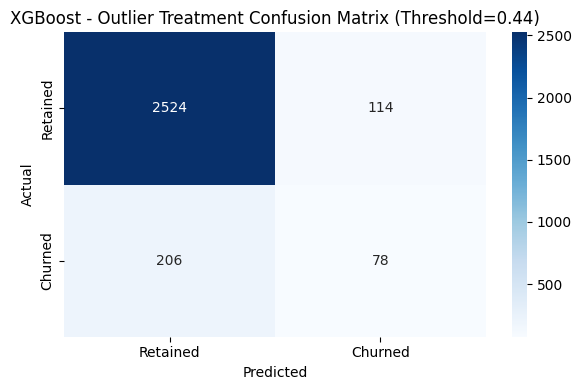

In [33]:
cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'XGBoost - Outlier Treatment Confusion Matrix (Threshold={best_threshold:.2f})')
plt.tight_layout()
plt.show()

### 32. CLASSIFICATION REPORT

In [34]:
print("\n==== CLASSIFICATION REPORT ====")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.92      0.96      0.94      2638
     Churned       0.41      0.27      0.33       284

    accuracy                           0.89      2922
   macro avg       0.67      0.62      0.63      2922
weighted avg       0.87      0.89      0.88      2922



### 33. CROSS VALIDATION PERFORMANCE

In [35]:
# Diagnostic CV on the selected model; these scores are not an unbiased
# estimate because the same training partition was used during tuning.
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_xgb_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

### 34. CROSS VALIDATION TRAIN SCORES

In [36]:
print("\n==== CROSS VALIDATION TRAIN SCORES ====")
for key, value in cv_results.items():
    if key.startswith('train'):
        print(f"{key} - Mean: {np.mean(value):.4f}, Std: {np.std(value):.4f}")


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9928, Std: 0.0009
train_Precision - Mean: 0.9596, Std: 0.0062
train_Recall - Mean: 0.9664, Std: 0.0054
train_F1 - Mean: 0.9630, Std: 0.0048
train_ROC_AUC - Mean: 0.9993, Std: 0.0001
train_PR_AUC - Mean: 0.9930, Std: 0.0014


### 35. CROSS VALIDATION VALIDATION SCORES

In [37]:
print("\n==== CROSS VALIDATION VALIDATION SCORES ====")
for key, value in cv_results.items():
    if key.startswith('test'):
        print(f"{key} - Mean: {np.mean(value):.4f}, Std: {np.std(value):.4f}")


==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.8976, Std: 0.0050
test_Precision - Mean: 0.4377, Std: 0.0587
test_Recall - Mean: 0.1872, Std: 0.0286
test_F1 - Mean: 0.2618, Std: 0.0369
test_ROC_AUC - Mean: 0.6884, Std: 0.0188
test_PR_AUC - Mean: 0.2814, Std: 0.0373


### 36. FEATURE IMPORTANCE

In [38]:
xgb_model = best_xgb_pipeline.named_steps['model']
feature_names = best_xgb_pipeline.named_steps['preprocessing'].get_feature_names_out()
importances = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20).round(5).to_string(index=False))


==== TOP 20 IMPORTANT FEATURES ====
                                       Feature  Importance
    origin_up_lxidpiddsbxsbosboudacockeimpuepw     0.02307
    origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws     0.02123
              discount_consumption_interaction     0.01867
                                        tenure     0.01536
                                 renewal_month     0.01469
                            margin_net_pow_ele     0.01449
channel_sales_lmkebamcaaclubfxadlmueccxoimlema     0.01416
                  midpeak_offpeak_var_relative     0.01326
                                   peak_fix_cv     0.01291
                       off_peak_peak_fix_ratio     0.01199
                     dec_jan_mid_peak_fix_diff     0.01194
                           var_year_price_peak     0.01152
                              margin_per_power     0.01146
                             var_6m_price_peak     0.01112
                      forecast_discount_energy     0.01110
                   

### 37. FEATURE IMPORTANCE VISUALIZATION

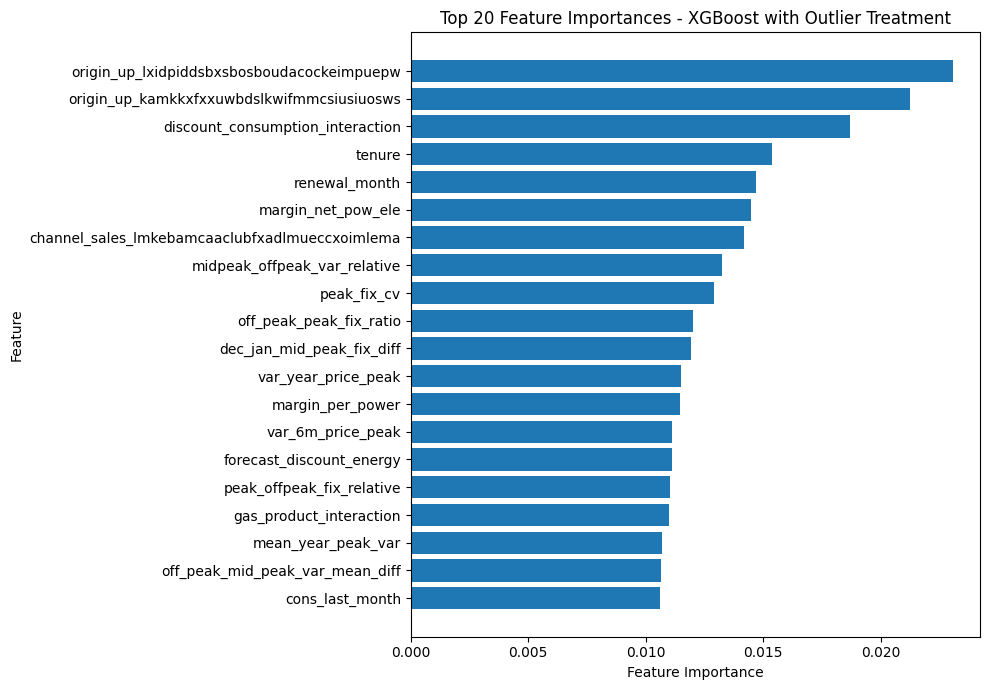

In [39]:
top_features = feature_importance_df.head(20).sort_values(
    by='Importance', ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - XGBoost with Outlier Treatment')
plt.tight_layout()
plt.show()

### 38. SAVE EXPERIMENT RESULTS

In [40]:
test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=['Exp9_4_XGBoost_Outlier_Treatment']
)

print("\n================================================")
print("EXP 9(4) - XGBOOST OUTLIER TREATMENT COMPLETED")
print("================================================")
print("Best CV PR-AUC:", round(random_search.best_score_, 4))
print("Selected Threshold:", round(best_threshold, 2))
print("Test PR-AUC:", round(test_metrics['PR-AUC'], 4))
print("Test F1:", round(test_metrics['F1 Score'], 4))


EXP 9(4) - XGBOOST OUTLIER TREATMENT COMPLETED
Best CV PR-AUC: 0.2814
Selected Threshold: 0.44
Test PR-AUC: 0.3257
Test F1: 0.3277


# Observation : **Exp 9(4) – Hyperparameter-Tuned XGBoost | Feature-Specific Outlier Capping**

**1. Outlier Treatment**

- Applied feature-specific outlier capping to 11 numerical features.
- Two-sided capping applied to:
  - `cons_last_month_diff`
  - `forecast_cons_diff`
  - `price_consumption_exposure`
- Upper-only capping applied to:
  - `consumption_per_power`
  - `cons_12m`
  - `cons_last_month`
  - `pow_max`
  - `forecast_cons_year`
  - `imp_cons`
  - `net_margin`
  - `margin_per_product`

**Observation:**

- Applied outlier capping to selected numerical features instead of removing entire records.
- Dataset size remained unchanged after capping.
- Missing values remained unchanged (21,569 in model training data).
- The experiment evaluates whether limiting extreme values improves XGBoost performance and generalization.

**2. Model Optimization**

- Applied hyperparameter tuning using 30 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Applied `scale_pos_weight` to handle class imbalance.
- Best hyperparameters:
  - `n_estimators`: 500
  - `max_depth`: 6
  - `learning_rate`: 0.03
  - `subsample`: 0.9
  - `colsample_bytree`: 1.0
  - `min_child_weight`: 3
  - `scale_pos_weight`: 4.647
  - `gamma`: 0.1
  - `reg_alpha`: 0.01
  - `reg_lambda`: 5
- Best CV PR-AUC: **28.14%**

**Observation:**

- The selected configuration uses 500 trees with a maximum depth of 6 and a learning rate of 0.03.
- Class weighting was used to give greater importance to the minority churn class.
- CV PR-AUC of 28.14% is slightly lower than Exp6 (28.63%).
- Training performance remains extremely high, indicating significant overfitting.

**3. Model Performance – Test Data**

- Accuracy: **89.05%**
- Precision: **40.62%**
- Recall: **27.46%**
- F1 Score: **32.77%**
- ROC-AUC: **68.66%**
- PR-AUC: **32.57%**

**4. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.44**, based on the highest F1 score in the threshold analysis.
- At threshold 0.44 (threshold validation):
  - Precision: 44.65%
  - Recall: 31.28%
  - F1 Score: 36.79%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**Observation:**

- The selected threshold provides a better balance between precision and recall on validation data.
- Precision increases as the threshold increases, while recall decreases.
- The threshold of 0.44 prioritizes better precision while retaining a reasonable level of recall.

**5. Confusion Matrix (Threshold = 0.44)**

- True Negatives: 2,524
- False Positives: 114
- False Negatives: 206
- True Positives: 78

**Observation:**

- Model correctly identifies 78 churn customers out of 284.
- It misses 206 actual churn customers.
- False positives are relatively low (114).
- The model is effective at avoiding unnecessary churn alerts but misses a large proportion of actual churn customers.
- Recall remains a major limitation.

**6. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 32.57% indicates reasonable churn identification capability.

**Observation:**

- The model performs better than random classification.
- Precision decreases as recall increases, indicating a trade-off between identifying more churn customers and maintaining prediction accuracy.
- Despite reasonable PR-AUC, the selected threshold produces relatively low recall.

**7. Cross-Validation Results**

- Training PR-AUC: 99.30%
- Validation accuracy: 89.76%
- Validation precision: 43.77%
- Validation recall: 18.72%
- Validation F1: 26.18%
- Validation ROC-AUC: 68.84%
- Validation PR-AUC: 28.14%

**Observation:**

- Significant training-validation performance gap indicates overfitting.
- Training PR-AUC is 99.30%, whereas validation PR-AUC is only 28.14%.
- Validation recall is low at the default 0.50 threshold.
- The model struggles to identify churn customers consistently despite achieving reasonable precision.

**8. Top 20 Important Features**

The most important features include:

- `origin_up_lxidpiddsbxsbosboudacockeimpuepw`
- `origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws`
- `discount_consumption_interaction`
- `tenure`
- `renewal_month`
- `margin_net_pow_ele`
- `channel_sales_lmkebamcaaclubfxadlmueccxoimlema`
- `midpeak_offpeak_var_relative`
- `peak_fix_cv`
- `off_peak_peak_fix_ratio`

**Observation:**

- Customer origin and channel-related features have high importance.
- Newly engineered features such as `discount_consumption_interaction` and `midpeak_offpeak_var_relative` contribute to predictions.
- `tenure` and `renewal_month` are also important.
- Feature importance differs from earlier Random Forest experiments, indicating that XGBoost uses a different combination of customer, pricing and consumption patterns.

**9. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strong Reg. RF | Exp4-XGBoost | Exp5-Strong Reg. XGB | Exp6-LightGBM | Exp7-SVM | Exp8(2)-RF | Exp9(2)-Capped RF | Exp9(4)-Capped XGB |
| --------- | ---------------- | ------------------- | ------------------- | ------------ | -------------------- | ------------- | -------- | ---------- | ----------------- | ------------------ |
| Accuracy  | 84.02%           | 87.34%              | 84.94%              | **89.39%**   | 86.69%               | 88.02%        | 82.75%   | 82.07%     | 82.20%            | 89.05%             |
| Precision | 26.72%           | 34.86%              | 29.26%              | **43.09%**   | 31.83%               | 36.48%        | 23.68%   | 25.71%     | 25.72%            | 40.62%             |
| Recall    | 36.97%           | 34.86%              | 38.73%              | 28.52%       | 32.39%               | 31.34%        | 34.86%   | **44.72%** | 44.01%            | 27.46%             |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%              | 34.32%       | 32.11%               | 33.71%        | 28.21%   | 32.65%     | 32.47%            | 32.77%             |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%              | 69.24%       | 69.58%               | 69.33%        | 66.45%   | 69.98%     | 69.10%            | 68.66%             |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%              | 32.15%       | 29.42%               | 32.20%        | 20.13%   | 34.26%     | 32.43%            | 32.57%             |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%              | 28.42%       | 26.38%               | 28.63%        | 20.85%   | 27.35%     | 26.98%            | 28.14%             |

**Observation:**

- Exp9(4) achieves the second-highest test accuracy (89.05%) and precision (40.62%) among all experiments.
- Test PR-AUC is 32.57%, slightly higher than Exp4-XGBoost (32.15%).
- However, its recall is only 27.46%, which is lower than most previous experiments.
- It generates only 114 false positives, considerably fewer than Exp8(2) and Exp9(2).
- Its CV PR-AUC (28.14%) is lower than Exp6 (28.63%) and Exp4 (28.42%).
- Outlier capping has not produced a consistent improvement in overall churn prediction performance.

**10. Final Conclusion – Exp 9(4) XGBoost with Feature-Specific Outlier Capping**

- Achieves a test PR-AUC of 32.57%.
- Precision improves to 40.62%, indicating better reliability when predicting churn.
- Correctly identifies 78 churn customers out of 284.
- Generates only 114 false positives.
- However, recall is relatively low at 27.46%, missing 206 actual churn customers.
- Significant overfitting remains despite outlier treatment.
- Outlier capping has not substantially improved overall predictive performance.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%).

Exp9(4) is an alternative when reducing false positives and improving precision are important. However, its low recall makes it less suitable when identifying as many potential churn customers as possible is the priority.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.44 threshold. Compare classification metrics cautiously.